In [16]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [17]:
data=load_breast_cancer()
X=data.data
y=data.target

In [18]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

In [19]:
scaler=StandardScaler()

In [20]:
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [21]:
model=SVC(kernel='linear')

In [22]:
model.fit(X_train_scaled,y_train)

SVC(kernel='linear')

In [23]:
y_pred=model.predict(X_test_scaled)

In [24]:
accuracy=accuracy_score(y_test,y_pred)

In [25]:
print(f"Точность модели SVM: {accuracy * 100:.2f}%")

Точность модели SVM: 97.66%


In [26]:
X_train_2d = X_train_scaled[:, :2] # Используем только два признака
model_2d = SVC(kernel='linear')
model_2d.fit(X_train_2d, y_train)

SVC(kernel='linear')

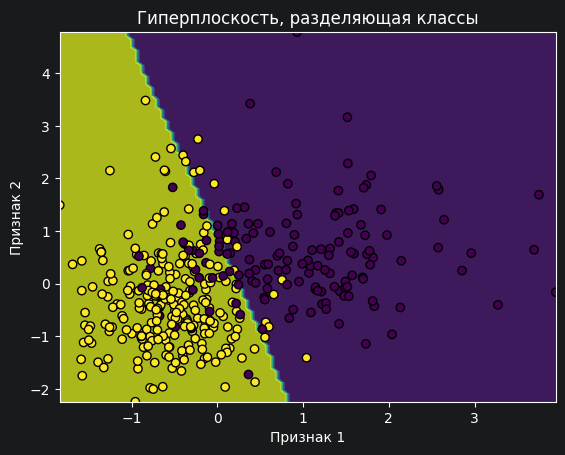

In [27]:
xx, yy = np.meshgrid(np.linspace(X_train_2d[:, 0].min(), X_train_2d[:, 0].max(), 100),
np.linspace(X_train_2d[:, 1].min(), X_train_2d[:, 1].max(), 100))
Z = model_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, alpha=0.8)
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolors='k', marker='o')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.title('Гиперплоскость, разделяющая классы')
plt.show()

Объяснение:
1. Загрузка данных: В примере используется набор данных о раковых клетках, который
содержит признаки клеток и их классы: 0 — злокачественные, 1 — доброкачественные.
2. Масштабирование данных: С помощью `StandardScaler` данные приводятся к единому
масштабу, что важно для эффективной работы SVM, так как он чувствителен к различным
масштабам признаков.
3. Создание модели: Мы создаем модель SVM с линейным ядром (`kernel='linear'`),
поскольку в этом примере данные линейно разделимы.
4. Обучение модели: Модель обучается на обучающих данных.
5. Предсказания и оценка точности: Мы проверяем точность модели на тестовых данных,
сравнив предсказанные значения с реальными.
6. Визуализация гиперплоскости: Для упрощения визуализации мы берем только два
признака (для двумерного представления) и строим график гиперплоскости, разделяющей
два класса.
Результат: После обучения модель SVM способна классифицировать новые данные,
предсказывая, является ли клетка здоровой или раковой. Точность классификации
оценивается с помощью метрики `accuracy`, и на графике можно увидеть, как
гиперплоскость разделяет два класса (здоровые и раковые клетки).